# The Hatch C2 · Churn · Clasificación

Preparación → train/test → entrenamiento y validación cruzada → evaluación → interpretación.
Este notebook se ejecuta de forma independiente. Seleccioná el kernel del entorno
del proyecto y ejecutá **Run All**. Ver `../README.md` para instalar dependencias.

| Datos | Fuente |
| --- | --- |
| `data/WA_Fn-UseC_-Telco-Customer-Churn.csv` | [Telco Customer Churn · BlastChar · Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn), descarga directa, versión 1 |

El CSV se lee localmente desde `data/`, sin descargas.

Churn es un dataset de muestra de IBM según Kaggle.


### 1. Configuración

Preparamos las variables numéricas con mediana y escalado; las categóricas con
moda y one-hot. Cada fold ajusta su propio Pipeline: ni la imputación ni el escalado
aprenden del test. Usamos 80/20 y semilla 42.


In [ ]:
# Bibliotecas para configuración del entorno.
import sys
from pathlib import Path
import warnings

# Herramientas para el análisis de datos y los gráficos.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Componentes de preparación, entrenamiento y evaluación de modelos.
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Detectar problemas de convergencia y localizar los CSV desde la raíz o notebooks/.
warnings.filterwarnings('error', category=ConvergenceWarning)
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'data').is_dir():
    PROJECT_DIR = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / 'data'
if not DATA_DIR.is_dir():
    raise FileNotFoundError('Ejecutá el notebook desde la raíz del proyecto o notebooks/.')
print('Python:', sys.executable)


def pipeline(X, modelo):
    # Identificar las variables numéricas para aplicar su preparación.
    numericas = X.select_dtypes('number').columns

    # Imputar y escalar numéricas; imputar y codificar categóricas.
    preparar = ColumnTransformer(
        [
            (
                'num',
                make_pipeline(
                    SimpleImputer(strategy='median'),
                    StandardScaler(),
                ),
                numericas,
            ),
            (
                'cat',
                make_pipeline(
                    SimpleImputer(strategy='most_frequent'),
                    OneHotEncoder(
                        drop='first',
                        handle_unknown='ignore',
                        sparse_output=False,
                    ),
                ),
                X.columns.difference(numericas),
            ),
        ]
    )

    # Integrar la preparación y el modelo en un único Pipeline.
    return Pipeline([('preparar', preparar), ('modelo', modelo)])


## 2. Churn · Diagnóstico y preparación

Usamos nueve variables predefinidas para simplificar la práctica. Excluimos el
identificador de cliente. `Churn=Yes` es la clase positiva (1). Los blancos en
`TotalCharges` se convierten a NaN y se imputan dentro del Pipeline, sin borrar clientes.
El split estratificado y los folds estratificados conservan la proporción de clases.


In [ ]:
# Cargar los clientes y comprobar los identificadores y las clases del objetivo.
churn = pd.read_csv(DATA_DIR / 'WA_Fn-UseC_-Telco-Customer-Churn.csv')
assert churn.customerID.is_unique and set(churn.Churn.unique()) == {'Yes', 'No'}

# Convertir los cargos totales a números; los valores inválidos quedan faltantes.
churn['TotalCharges'] = pd.to_numeric(churn.TotalCharges, errors='coerce')
display(churn.head(3))
print(
    'Dimensiones:',
    churn.shape,
    '| TotalCharges faltantes:',
    churn.TotalCharges.isna().sum(),
)

# Revisar la cantidad de clientes en cada clase.
display(churn.Churn.value_counts().rename('clientes').to_frame())

# Seleccionar las variables predictoras y codificar churn como 0 y 1.
columnas = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges',
    'Contract',
    'InternetService',
    'OnlineSecurity',
    'TechSupport',
    'PaymentMethod',
    'PaperlessBilling',
]
Xc, yc = churn[columnas], churn.Churn.map({'No': 0, 'Yes': 1})

# Dividir en train y test conservando la proporción de clases.
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc,
    yc,
    test_size=.2,
    stratify=yc,
    random_state=42,
)
print(
    'Train/test:',
    len(Xc_train),
    len(Xc_test),
    '| Churn train/test:',
    yc_train.mean(),
    yc_test.mean(),
)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


Dimensiones: (7043, 21) | TotalCharges faltantes: 11


,clientes
Churn,
No,5174
Yes,1869


Train/test: 5634 1409 | Churn train/test: 0.2653532126375577 0.2654364797728886


### Entrenamiento: mayoría y regresión logística

La logística convierte una combinación lineal en una probabilidad mediante la
sigmoide. Comparamos la clase mayoritaria, logística normal y balanceada.
Seleccionamos `C` (menor = más regularización L2) y ponderación por **F1 de CV**.
El umbral se mantiene en 0.5. La ponderación balanceada prioriza la clase minoritaria;
no garantiza probabilidades calibradas.


In [ ]:
# Comparar la clase mayoritaria con distintas configuraciones de logística.
grid_c = [
    {'modelo': [DummyClassifier(strategy='most_frequent')]},
    {
        'modelo': [LogisticRegression(max_iter=5000)],
        'modelo__C': [.01, 1, 10],
        'modelo__class_weight': [None, 'balanced'],
    },
]

# Seleccionar la configuración según F1 con validación cruzada estratificada.
busqueda_c = GridSearchCV(
    pipeline(Xc_train, LogisticRegression()),
    grid_c,
    scoring='f1',
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    error_score='raise',
).fit(Xc_train, yc_train)

# Ordenar los resultados de validación cruzada para facilitar la comparación.
cv_c = pd.DataFrame(
    {
        'F1_CV': busqueda_c.cv_results_['mean_test_score'],
        'parametros': busqueda_c.cv_results_['params'],
    }
)
display(cv_c.sort_values('F1_CV', ascending=False))

# Guardar el modelo seleccionado y mostrar sus parámetros.
ganador_c = busqueda_c.best_estimator_
print('Elegido por CV:', busqueda_c.best_params_)


,F1_CV,parametros
2,0.627536,"{'modelo': LogisticRegression(max_iter=5000), ..."
6,0.621531,"{'modelo': LogisticRegression(max_iter=5000), ..."
4,0.620623,"{'modelo': LogisticRegression(max_iter=5000), ..."
5,0.582434,"{'modelo': LogisticRegression(max_iter=5000), ..."
3,0.581315,"{'modelo': LogisticRegression(max_iter=5000), ..."
1,0.549301,"{'modelo': LogisticRegression(max_iter=5000), ..."
0,0.000000,{'modelo': DummyClassifier(strategy='most_freq...


Elegido por CV: {'modelo': LogisticRegression(max_iter=5000), 'modelo__C': 0.01, 'modelo__class_weight': 'balanced'}


### Evaluación e interpretación

| Métrica | Qué responde |
| --- | --- |
| Accuracy | ¿Qué fracción de clientes clasifiqué correctamente? |
| Precision | De mis alertas de churn, ¿qué fracción era churn? |
| Recall | De las bajas observadas, ¿qué fracción detecté? |
| F1 | ¿Cómo se combinan precision y recall? |

Una falsa alerta (FP) apunta a alguien que no se fue; una baja omitida (FN) queda
sin detectar. La matriz usa filas reales y columnas predichas: `[[TN, FP], [FN, TP]]`.
Los ceros del baseline se reportan con `zero_division=0` porque no genera alertas.


,accuracy,precision,recall,F1
modelo,,,,
Mayoría,0.7346,0.0000,0.0000,0.000
Logística elegida por CV,0.7381,0.5043,0.7781,0.612


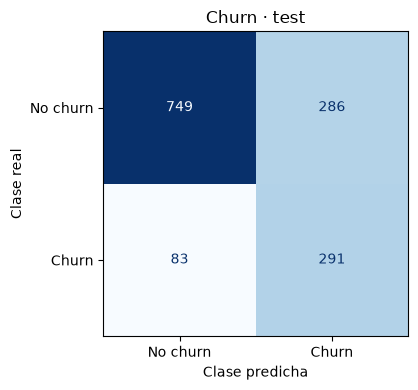

,coef_log_odds,odds_ratio
num__tenure,-0.681,0.506
cat__Contract_Two year,-0.596,0.551
cat__OnlineSecurity_Yes,-0.370,0.691
cat__Contract_One year,-0.366,0.693
cat__TechSupport_Yes,-0.341,0.711
cat__InternetService_No,-0.229,0.795
cat__OnlineSecurity_No internet service,-0.229,0.795
cat__TechSupport_No internet service,-0.229,0.795
num__TotalCharges,-0.109,0.896
cat__PaymentMethod_Credit card (automatic),-0.096,0.909


Referencias categóricas: {'Contract': 'Month-to-month', 'InternetService': 'DSL', 'OnlineSecurity': 'No', 'PaperlessBilling': 'No', 'PaymentMethod': 'Bank transfer (automatic)', 'TechSupport': 'No'}


C:\Users\Lucas\AppData\Local\Temp\ipykernel_772\2874303745.py:65: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  Xc_train.select_dtypes('object').columns.sort_values(),


Bajas detectadas: **291/374**; omitidas: **83**; falsas alertas: **286**. Accuracy de la mayoría: **73.5%**, con recall cero.

In [ ]:
# Entrenar la referencia que siempre predice la clase mayoritaria.
baseline_c = pipeline(
    Xc_train,
    DummyClassifier(strategy='most_frequent'),
).fit(Xc_train, yc_train)

# Evaluar la referencia y el modelo seleccionado sobre los mismos datos de test.
filas_c = []

for nombre, modelo in [
    ('Mayoría', baseline_c),
    ('Logística elegida por CV', ganador_c),
]:
    pred = modelo.predict(Xc_test)
    filas_c.append(
        [
            nombre,
            accuracy_score(yc_test, pred),
            precision_score(yc_test, pred, zero_division=0),
            recall_score(yc_test, pred),
            f1_score(yc_test, pred, zero_division=0),
        ]
    )

test_c = pd.DataFrame(
    filas_c,
    columns=['modelo', 'accuracy', 'precision', 'recall', 'F1'],
).set_index('modelo')
display(test_c.round(4))

# Visualizar los aciertos y errores mediante la matriz de confusión.
fig, ax = plt.subplots(figsize=(5, 4))
matriz = ConfusionMatrixDisplay.from_predictions(
    yc_test,
    ganador_c.predict(Xc_test),
    display_labels=['No churn', 'Churn'],
    cmap='Blues',
    colorbar=False,
    ax=ax,
)
ax.set(title='Churn · test', xlabel='Clase predicha', ylabel='Clase real')
fig.tight_layout()
plt.show()
plt.close(fig)

# Extraer los resultados de la matriz y los coeficientes del modelo.
tn, fp, fn, tp = matriz.confusion_matrix.ravel()
coef_c = pd.Series(
    ganador_c['modelo'].coef_[0],
    index=ganador_c['preparar'].get_feature_names_out(),
    name='coef_log_odds',
).sort_values()
display(
    pd.DataFrame(
        {'coef_log_odds': coef_c, 'odds_ratio': np.exp(coef_c)}
    ).round(3)
)

# Mostrar la categoría de referencia utilizada en cada variable categórica.
print(
    'Referencias categóricas:',
    {
        col: valores[0]
        for col, valores in zip(
            Xc_train.select_dtypes('object').columns.sort_values(),
            ganador_c['preparar'].named_transformers_['cat'][-1].categories_,
        )
    },
)

# Resumir las bajas detectadas, las omitidas y las falsas alertas.
display(
    Markdown(
        f"Bajas detectadas: **{tp}/{tp + fn}**; omitidas: **{fn}**; falsas alertas: **{fp}**. "
        f"Accuracy de la mayoría: **{test_c.loc['Mayoría', 'accuracy']:.1%}**, con recall cero."
    )
)


### ¿Qué significan estos resultados para Churn?

**La accuracy por sí sola oculta el problema.** Decir que ningún cliente se va
logra **73,46 % de accuracy**, pero no detecta ninguna de las 374 bajas del test.
La logística obtiene **73,81 %**, apenas más, y aun así detecta **291 bajas**.
Su aporte se ve al mirar precision y recall, no solo el porcentaje total de aciertos.

Con el umbral de 0,5, los resultados concretos son:

- **Recall de 77,81 %:** identifica 291 de 374 bajas, aproximadamente 8 de cada 10.
  Las **83 restantes** quedan sin detectar.
- **Precision de 50,43 %:** de las **577 alertas**, 291 corresponden a bajas reales
  y **286 son falsas alertas**. Aproximadamente una de cada dos alertas es correcta.
- **F1 de 0,612:** resume precision y recall mediante su media armónica. Mejora
  frente al cero del baseline, pero no demuestra por sí solo que una campaña sea rentable.

En una aplicación de retención, esto supondría revisar bastantes clientes que no
se fueron para identificar una parte importante de las bajas. Puede ser aceptable
si revisar una alerta cuesta poco y perder un cliente cuesta mucho. Si cada alerta
implica un descuento caro, las falsas alertas pueden pesar más. Faltan esos costos
para elegir un umbral de negocio; cualquier ajuste se validaría dentro de train.
Además, detectar una baja no demuestra que una intervención logre evitarla.

**¿Qué nos dicen los coeficientes?** Manteniendo los otros predictores constantes,
un contrato de dos años tiene unas **odds de churn 0,55 veces** las de uno mensual
en el modelo. Una desviación estándar más de antigüedad (`tenure`) se asocia con
unas odds de **0,51 veces**. Las odds son la razón entre la probabilidad de baja y
la de permanencia: reducirlas a la mitad no equivale a reducir a la mitad la
probabilidad. Estos resultados describen asociaciones, no prueban que cambiar el
contrato cause una reducción de bajas. La ponderación balanceada tampoco garantiza
que las probabilidades predichas estén calibradas.


## 3. Conclusiones y límites

La logística detecta cerca del **78 % de las bajas**, a cambio de que casi la mitad
de sus alertas sean falsas. El valor práctico depende del costo de esas alertas y
de las bajas que quedan sin detectar. Precision y recall ayudan a evaluar estas
consecuencias; la accuracy por sí sola no basta.

La selección de modelos y parámetros usa CV en train; después de observar test
no reajustamos los modelos. Los mejores puntajes de CV pueden ser optimistas por
la búsqueda de parámetros. Las cifras comentadas corresponden a la ejecución
original, con semilla 42 y los CSV locales.

- Es una clasificación retrospectiva de un dataset de muestra. Sin fechas que
  prueben la disponibilidad previa de los predictores, no afirmamos anticipación futura.
- **Siguiente paso:** definir costos y evaluar umbrales dentro de train. Si las
  decisiones se toman después de este análisis, hará falta un nuevo conjunto
  independiente para evaluar la versión final sin reutilizar este test como
  criterio de selección.
